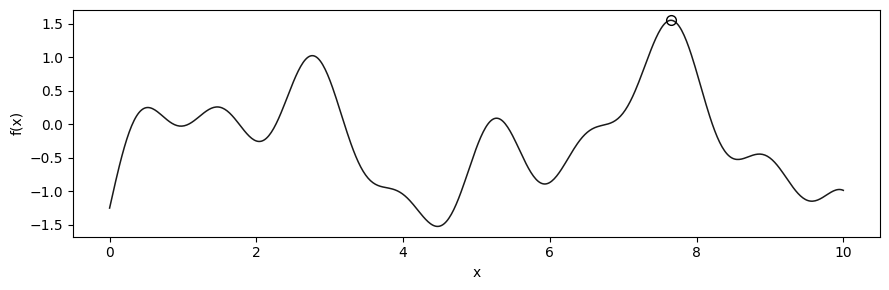

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random


# Experiment 1: Plot a function
xs = np.linspace(0, 10, 600)
fx = (
    np.sin(xs)
    + 0.6 * np.sin(2.7 * xs)
    + 0.35 * np.sin(5.1 * xs)
    - 0.05 * (xs - 5) ** 2
)

plt.figure(figsize=(9, 3))
plt.plot(xs, fx, lw=1.1, color='0.1')
plt.plot(xs[np.argmax(fx)], fx.max(), 'o', ms=7, mfc='none', mec='k')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.tight_layout()
plt.show()

In [ ]:
# Experiment 2: Hill climbing for the N-Queens problem
def conflicts(board):
    n = len(board)
    bad = 0

    for i in range(n):
        for j in range(i + 1, n):
            if (
                board[i] == board[j]
                or abs(board[i] - board[j]) == abs(i - j)
            ):
                bad += 1

    return bad


def hill_climb(n=8, seed=0):
    """Steepest ascent. Returns True if a conflict-free board is reached."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]  # a complete, random board

    while True:
        current = conflicts(board)

        if current == 0:
            return True  # solved

        best, move = current, None

        for c in range(n):  # try every single-queen move
            old = board[c]

            for row in range(n):
                if row == old:
                    continue

                board[c] = row
                v = conflicts(board)

                if v < best:
                    best, move = v, (c, row)

            board[c] = old

        if move is None:
            return False  # local minimum: stuck

        board[move[0]] = move[1]


# Experiment 3: Random restarts
def hill_climb_restarts(n=8, restarts=10, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed * 1000 + k):
            return True

    return False


trials = 100

plain = sum(hill_climb(6, seed=s) for s in range(trials)) / trials
print(f'plain hill climbing: {100 * plain:.1f}% of {trials} random starts')

for k in (1, 2, 5, 10, 20, 24, 27, 32, 40, 48, 55, 63):
    ok = sum(
        hill_climb_restarts(6, k, seed=1000 + s)
        for s in range(trials)
    ) / trials

    print(f'{k:>3} restarts: {100 * ok:.1f}%')

plain hill climbing: 9.0% of 100 random starts
  1 restarts: 10.0%
  2 restarts: 28.0%
  5 restarts: 47.0%
 10 restarts: 71.0%
 20 restarts: 88.0%
 24 restarts: 91.0%
 27 restarts: 93.0%
 32 restarts: 95.0%
 40 restarts: 99.0%
 48 restarts: 100.0%
 55 restarts: 100.0%
 63 restarts: 100.0%


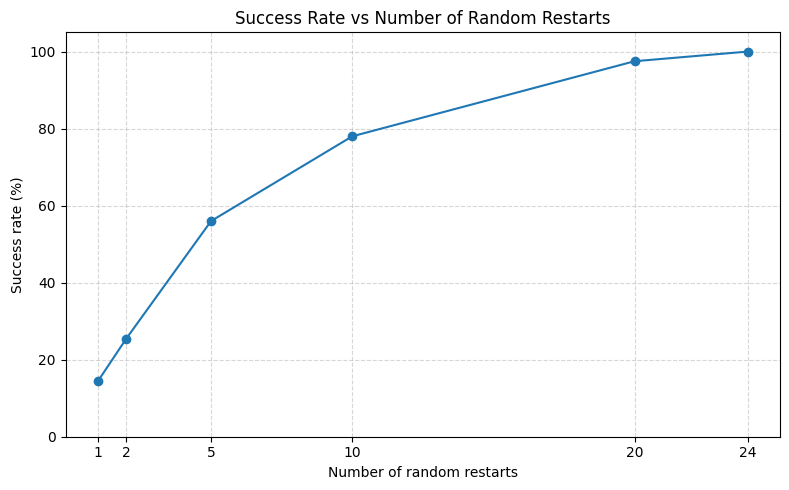

In [ ]:
import matplotlib.pyplot as plt

# Number of random restarts
restarts = [1, 2, 5, 10, 20, 24]

# Success rate (%) from Experiment 3
rates = []

for k in restarts:
    ok = sum(
        hill_climb_restarts(8, k, seed=1000 + s)
        for s in range(trials)
    ) / trials

    rates.append(100 * ok)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(restarts, rates, marker='o', linewidth=1.5)

plt.xlabel('Number of random restarts')
plt.ylabel('Success rate (%)')
plt.title('Success Rate vs Number of Random Restarts')
plt.xticks(restarts)
plt.ylim(0, 105)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()